In [6]:
import numpy as np

In [7]:
import pandas as pd

In [8]:
import matplotlib.pyplot as plt

In [9]:
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder

In [10]:
import seaborn as sns

In [11]:
data=pd.read_csv("C:/Users/ELCOT/Downloads/India Agriculture Crop Production.csv (1).zip")

In [12]:
data.head()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-02,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-03,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-04,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-02,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-03,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296


In [13]:
data.tail()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
345402,Manipur,IMPHAL WEST,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345403,Manipur,SENAPATI,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345404,Manipur,TAMENGLONG,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345405,Manipur,THOUBAL,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN
345406,Manipur,UKHRUL,NaN,2019-20,Rabi,NaN,Hectare,NaN,Tonnes,NaN


In [14]:
data.size

3454070

In [15]:
data.shape

(345407, 10)

In [16]:
data.columns

Index(['State', 'District', 'Crop', 'Year', 'Season', 'Area', 'Area Units',
       'Production', 'Production Units', 'Yield'],
      dtype='str')

In [17]:
data.isnull().sum()

State                  0
District               0
Crop                  32
Year                   0
Season                 1
Area                  33
Area Units             0
Production          4993
Production Units       0
Yield                 33
dtype: int64

In [18]:
data.dropna(inplace=True)

In [19]:
data['Season']=data['Season'].fillna(data['Season'].mode()[0])

In [20]:
data.head()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-02,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-03,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-04,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-02,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-03,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296


In [22]:
data.dtypes

State                   str
District                str
Crop                    str
Year                    str
Season                  str
Area                float64
Area Units              str
Production          float64
Production Units        str
Yield               float64
dtype: object

In [23]:
data.info

<bound method DataFrame.info of                               State                  District      Crop  \
0       Andaman and Nicobar Islands                  NICOBARS  Arecanut   
1       Andaman and Nicobar Islands                  NICOBARS  Arecanut   
2       Andaman and Nicobar Islands                  NICOBARS  Arecanut   
3       Andaman and Nicobar Islands  NORTH AND MIDDLE ANDAMAN  Arecanut   
4       Andaman and Nicobar Islands            SOUTH ANDAMANS  Arecanut   
...                             ...                       ...       ...   
345370                  West Bengal           PURBA BARDHAMAN     Wheat   
345371                  West Bengal                   PURULIA     Wheat   
345372                  West Bengal                   PURULIA     Wheat   
345373                  West Bengal                   PURULIA     Wheat   
345374                  West Bengal                   PURULIA     Wheat   

           Year      Season    Area Area Units  Production Producti

In [24]:
data['Year']=pd.to_datetime(data['Year'].astype(str).str[:4],format='%Y',errors='coerce')
data['Year']
    

0        2001-01-01
1        2002-01-01
2        2003-01-01
3        2001-01-01
4        2002-01-01
            ...    
345370   2000-01-01
345371   1997-01-01
345372   1998-01-01
345373   1999-01-01
345374   2000-01-01
Name: Year, Length: 340414, dtype: datetime64[us]

In [25]:
data.loc[0:4]

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-01-01,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-01-01,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-01-01,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-01-01,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-01-01,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296


In [26]:
data.iloc[0:5,0:3]

,State,District,Crop
0,Andaman and Nicobar Islands,NICOBARS,Arecanut
1,Andaman and Nicobar Islands,NICOBARS,Arecanut
2,Andaman and Nicobar Islands,NICOBARS,Arecanut
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut


In [27]:
data.loc[0:4,['State','Crop','Production']]

,State,Crop,Production
0,Andaman and Nicobar Islands,Arecanut,2061.0
1,Andaman and Nicobar Islands,Arecanut,2083.0
2,Andaman and Nicobar Islands,Arecanut,1525.0
3,Andaman and Nicobar Islands,Arecanut,5239.0
4,Andaman and Nicobar Islands,Arecanut,5267.0


In [28]:
data[data['Production']>1000]

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-01-01,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-01-01,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-01-01,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-01-01,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-01-01,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296
...,...,...,...,...,...,...,...,...,...,...
345370,West Bengal,PURBA BARDHAMAN,Wheat,2000-01-01,Rabi,6310.0,Hectare,15280.0,Tonnes,2.421553
345371,West Bengal,PURULIA,Wheat,1997-01-01,Rabi,1895.0,Hectare,2760.0,Tonnes,1.456464
345372,West Bengal,PURULIA,Wheat,1998-01-01,Rabi,3736.0,Hectare,5530.0,Tonnes,1.480193
345373,West Bengal,PURULIA,Wheat,1999-01-01,Rabi,2752.0,Hectare,6928.0,Tonnes,2.517442


In [29]:
data[data['Crop']=='Arecanut']

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-01-01,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-01-01,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-01-01,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-01-01,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-01-01,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296
...,...,...,...,...,...,...,...,...,...,...
343306,West Bengal,NADIA,Arecanut,2000-01-01,Whole Year,264.0,Hectare,264.0,Tonnes,1.000000
343307,West Bengal,PURBA BARDHAMAN,Arecanut,1997-01-01,Whole Year,102.0,Hectare,295.0,Tonnes,2.892157
343308,West Bengal,PURBA BARDHAMAN,Arecanut,1998-01-01,Whole Year,106.0,Hectare,313.0,Tonnes,2.952830
343309,West Bengal,PURBA BARDHAMAN,Arecanut,1999-01-01,Whole Year,108.0,Hectare,320.0,Tonnes,2.962963


In [30]:
data['Production_Per_Area']=data['Production']/data['Area']

In [31]:
data.head()

,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield,Production_Per_Area
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-01-01,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-01-01,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-01-01,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-01-01,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-01-01,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296,1.696296


In [34]:
data.groupby('Crop')['Production'].sum()

Crop
Arecanut                 3.929935e+07
Arhar/Tur                6.126133e+07
Bajra                    2.006659e+08
Banana                   2.271978e+08
Barley                   3.506932e+07
Black pepper             2.097305e+06
Cardamom                 2.554982e+05
Cashewnut                3.740786e+06
Castor seed              2.794934e+07
Coconut                  3.108048e+11
Coriander                7.355899e+06
Cotton(lint)             4.839080e+08
Cowpea(Lobia)            7.455650e+05
Dry Ginger               4.943330e+03
Dry chillies             2.653439e+07
Garlic                   2.273346e+07
Ginger                   1.817897e+07
Gram                     1.602564e+08
Groundnut                1.638320e+08
Guar seed                3.132193e+07
Horse-gram               5.276757e+06
Jowar                    1.492559e+08
Jute                     2.304238e+08
Khesari                  7.115453e+06
Linseed                  3.298063e+06
Maize                    4.439912e+08
Masoor 

In [35]:
data.groupby('Season')['Production'].mean()

Season
Autumn        1.214891e+04
Kharif        4.129064e+04
Rabi          3.156612e+04
Summer        1.109338e+04
Whole Year    4.706073e+06
Winter        7.134624e+04
Name: Production, dtype: float64

In [40]:
le=LabelEncoder()
data['Crop_Label']=le.fit_transform(data['Crop'].astype(str))
data[['Crop_Label']].head()                                   

,Crop_Label
0,0
1,0
2,0
3,0
4,0


In [42]:
oe=OrdinalEncoder()
data[['Season_Ordinal']]=oe.fit_transform(data[['Season']].astype(str))
data[['Season','Season_Ordinal']].head()

,Season,Season_Ordinal
0,Kharif,1.0
1,Whole Year,4.0
2,Whole Year,4.0
3,Kharif,1.0
4,Whole Year,4.0


In [45]:
value=data['Production'].dropna()
value.mean()

np.float64(958371.148663977)

In [46]:
value.median()

np.float64(717.0)

In [47]:
value.mode()

0    1.0
Name: Production, dtype: float64

In [48]:
value.std()

np.float64(21529855.088423867)

In [49]:
value.var()

np.float64(463534660128531.1)

In [50]:
value.min()

np.float64(0.0)

In [51]:
value.max()

np.float64(1597800000.0)

In [53]:
value.max()-value.min()

np.float64(1597800000.0)

In [54]:
Q1=value.quantile(0.25)
Q2=value.quantile(0.50)
Q3=value.quantile(0.75)
IQR=Q3-Q1
value.skew()

np.float64(35.8749667706441)

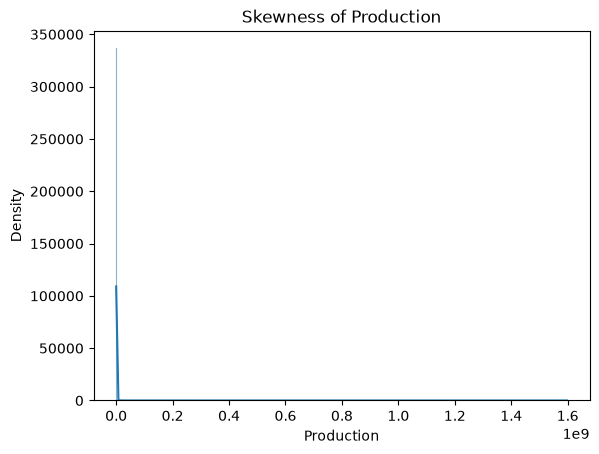

In [59]:
sns.histplot(data['Production'].dropna(), kde=True)
plt.title("Skewness of Production")
plt.xlabel("Production")
plt.ylabel("Density")
plt.show()

In [66]:
cv=(value.std()/value.mean())*100
("Coefficient of Variation:"